In [9]:
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score,precision_score,classification_report,recall_score

In [10]:
df = sns.load_dataset('titanic')

In [11]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 100.4 KB


In [13]:
df.isnull().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [25]:
features = ["pclass","sex","fare","age","embarked"]
target = ["survived"]

In [19]:
from sklearn.impute import SimpleImputer

imputer_median = SimpleImputer(strategy="median")
df["age"] = imputer_median.fit_transform(df[["age"]])

imputer_median = SimpleImputer(strategy="most_frequent")
df[["embarked"]] = imputer_median.fit_transform(df[["embarked"]])

In [20]:
df.isnull().sum()

survived         0
pclass           0
sex              0
age              0
sibsp            0
parch            0
fare             0
embarked         0
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [21]:
df["embarked"].value_counts()

embarked
S    646
C    168
Q     77
Name: count, dtype: int64

In [24]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()

df["sex"] = encoder.fit_transform(df["sex"])

df["embarked"] = encoder.fit_transform(df["embarked"])


In [26]:
x = df[features]
y = df[target]

In [27]:
x.head()

,pclass,sex,fare,age,embarked
0,3,1,7.2500,22.0,2
1,1,0,71.2833,38.0,0
2,3,0,7.9250,26.0,2
3,1,0,53.1000,35.0,2
4,3,1,8.0500,35.0,2


In [28]:
y.head()

,survived
0,0
1,1
2,1
3,1
4,0


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [30]:
X_train.head()

,pclass,sex,fare,age,embarked
331,1,1,28.5000,45.5,2
733,2,1,13.0000,23.0,2
382,3,1,7.9250,32.0,2
704,3,1,7.8542,26.0,2
813,3,0,31.2750,6.0,2


In [31]:
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier()

model.fit(X_train,y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [33]:
y_pred = model.predict(X_test)

In [34]:
print("Accuracy = ",accuracy_score(y_test,y_pred))

Accuracy =  0.770949720670391


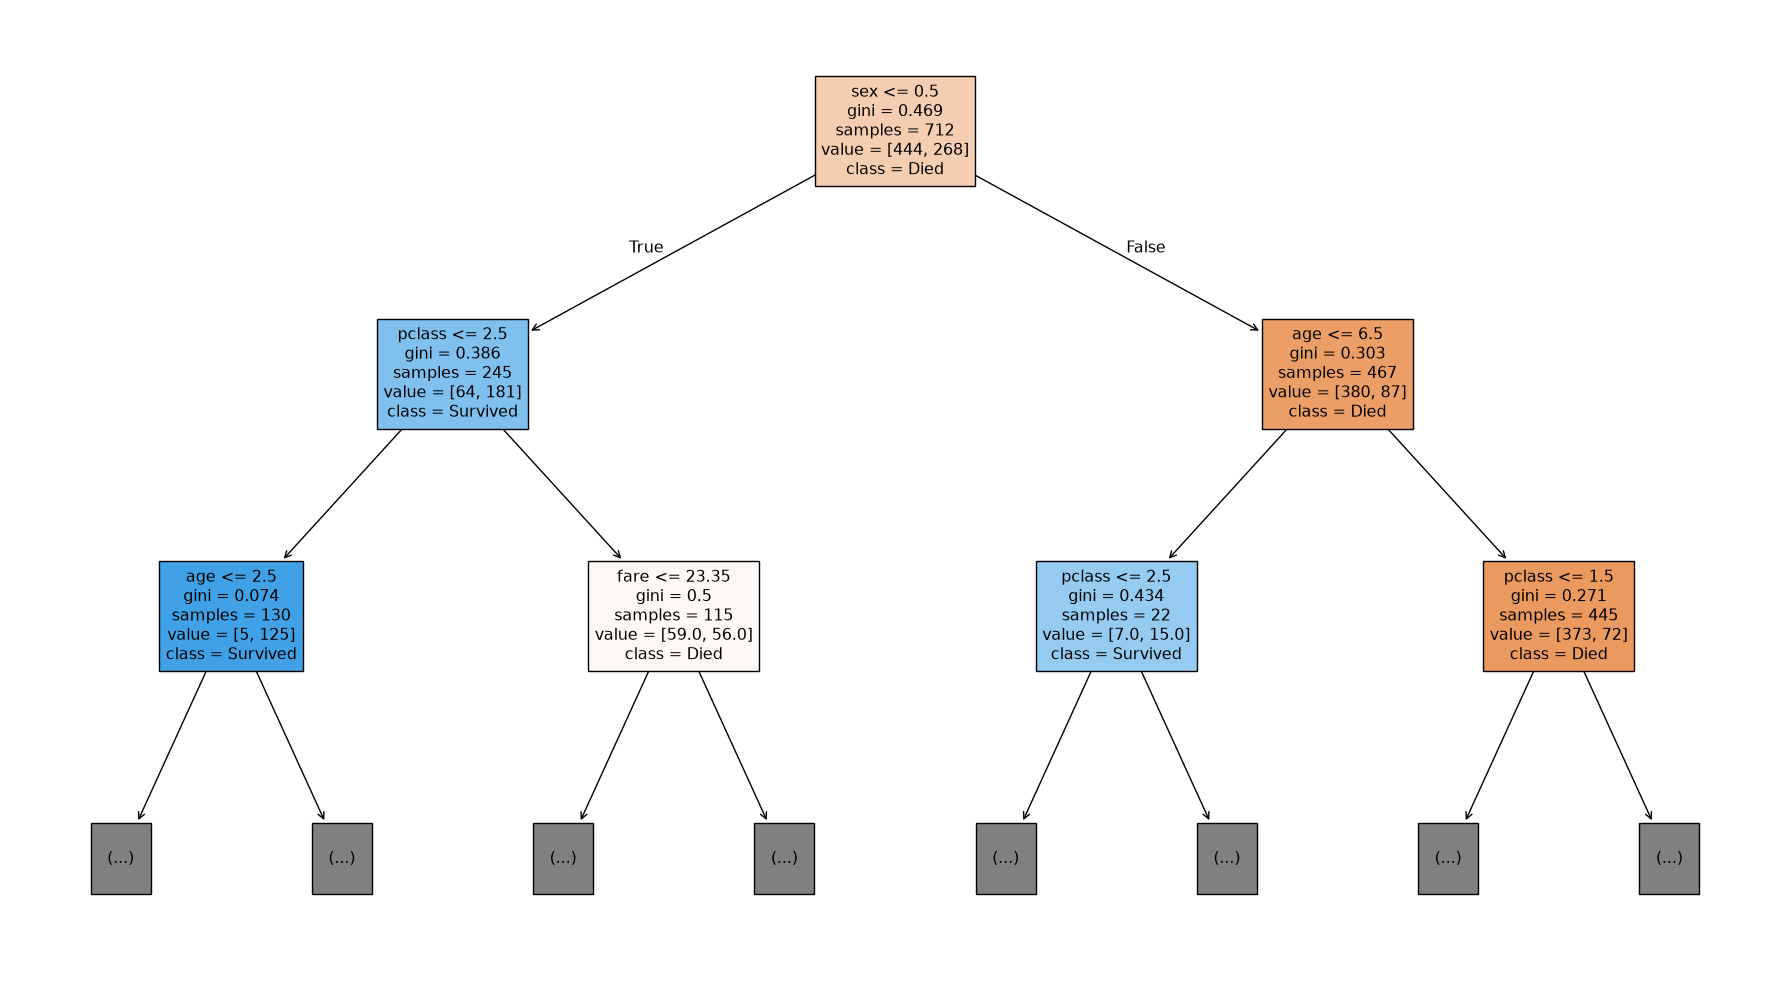

In [39]:
from sklearn.tree import plot_tree

plt.figure(figsize=(18,10))

plot_tree(
    model,
    feature_names=x.columns,
    class_names=["Died","Survived"],
    filled=True,
    max_depth=2
)

plt.tight_layout()
plt.show()


# Decision Tree with Pre - Pruning

In [43]:
max_depths = [2,3,4,5,6,7,8,9,10,11,12,13,14,15]
min_samples = [5,7,9,10,12,14,15,17,19,20,21,23,25,30]

best_acc = 0
best_depth = 0
best_min_samples = 0
for depth in max_depths:
    for samples in min_samples:

        model = DecisionTreeClassifier(max_depth=depth)
        model.fit(X_train,y_train)
        y_pred = model.predict(X_test)

        acc = accuracy_score(y_test,y_pred)
        if acc > best_acc:
            best_acc = acc
            best_depth = depth
            best_min_samples = samples
        print(f"for depth = {depth} Accuracy Score = ",acc)


    

for depth = 2 Accuracy Score =  0.7653631284916201
for depth = 2 Accuracy Score =  0.7653631284916201
for depth = 2 Accuracy Score =  0.7653631284916201
for depth = 2 Accuracy Score =  0.7653631284916201
for depth = 2 Accuracy Score =  0.7653631284916201
for depth = 2 Accuracy Score =  0.7653631284916201
for depth = 2 Accuracy Score =  0.7653631284916201
for depth = 2 Accuracy Score =  0.7653631284916201
for depth = 2 Accuracy Score =  0.7653631284916201
for depth = 2 Accuracy Score =  0.7653631284916201
for depth = 2 Accuracy Score =  0.7653631284916201
for depth = 2 Accuracy Score =  0.7653631284916201
for depth = 2 Accuracy Score =  0.7653631284916201
for depth = 2 Accuracy Score =  0.7653631284916201
for depth = 3 Accuracy Score =  0.7988826815642458
for depth = 3 Accuracy Score =  0.7988826815642458
for depth = 3 Accuracy Score =  0.7988826815642458
for depth = 3 Accuracy Score =  0.7988826815642458
for depth = 3 Accuracy Score =  0.7988826815642458
for depth = 3 Accuracy Score = 

In [44]:
print("Best Model")
print(f"max_depth = {best_depth} min_samples = {best_min_samples} and Accuracy = {best_acc}")

Best Model
max_depth = 10 min_samples = 21 and Accuracy = 0.8100558659217877


# Decision Tree with Post - Pruning

In [45]:
# using ccp_alpha
model = DecisionTreeClassifier(random_state=42)
model.fit(X_train,y_train)



,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


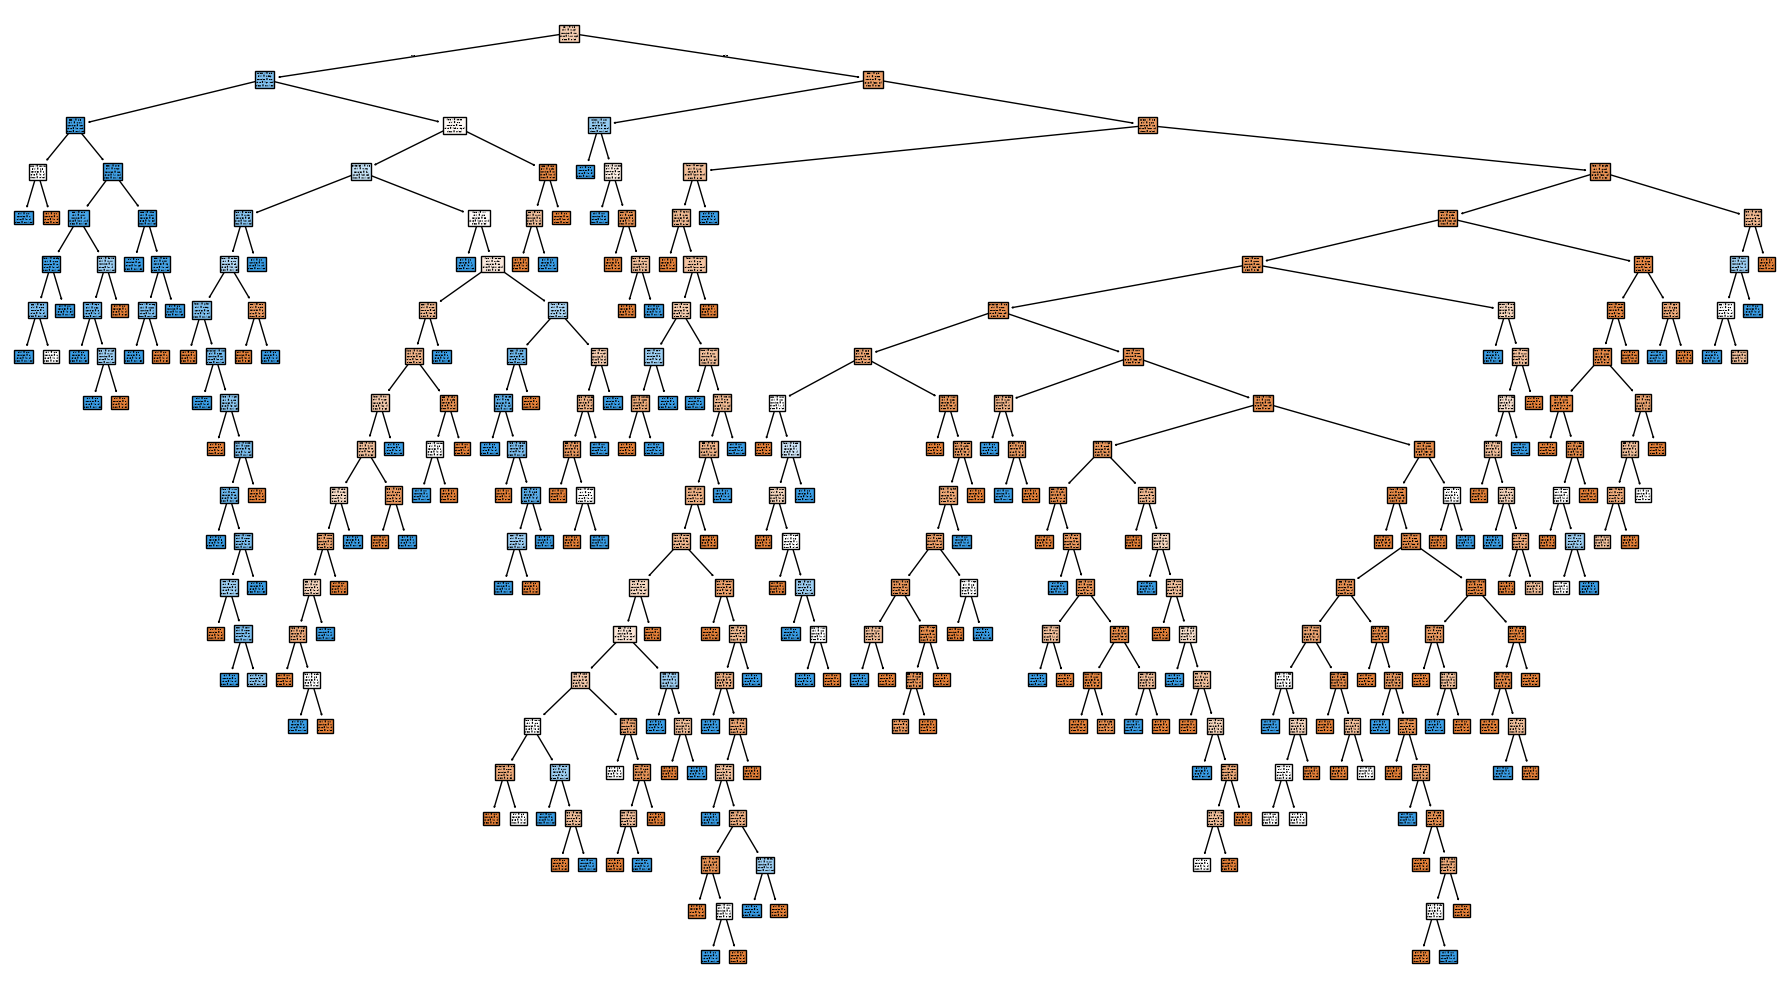

In [64]:
plt.figure(figsize=(18,10))

plot_tree(
    model,
    feature_names=x.columns,
    class_names=["Died","Survived"],
    filled=True,
    
)

plt.tight_layout()
plt.show()

In [47]:
paths = model.cost_complexity_pruning_path(X_train,y_train)

In [49]:
ccp_alphas = paths.ccp_alphas
print(ccp_alphas)

[0.00000000e+00 0.00000000e+00 6.68806849e-05 1.45921494e-04
 1.84428555e-04 2.00642055e-04 2.34082397e-04 2.34082397e-04
 3.51123596e-04 4.68164794e-04 4.68164794e-04 5.61797753e-04
 6.24219725e-04 6.67991230e-04 7.02247191e-04 7.02247191e-04
 8.19288390e-04 8.19288390e-04 8.32292967e-04 8.42696629e-04
 8.42696629e-04 8.42696629e-04 8.94231048e-04 8.99610781e-04
 9.24769963e-04 9.36329588e-04 9.36329588e-04 9.36329588e-04
 9.88347898e-04 1.00253471e-03 1.05337079e-03 1.07400895e-03
 1.08038029e-03 1.11865144e-03 1.12359551e-03 1.12359551e-03
 1.13139825e-03 1.17041199e-03 1.18841832e-03 1.22566125e-03
 1.22893258e-03 1.22893258e-03 1.24361593e-03 1.24843945e-03
 1.27565833e-03 1.30996111e-03 1.33761370e-03 1.37044603e-03
 1.46301498e-03 1.47927070e-03 1.51142557e-03 1.54072312e-03
 1.56675436e-03 1.60434338e-03 1.66892062e-03 1.76144762e-03
 1.86751451e-03 2.10674157e-03 2.34082397e-03 2.41226470e-03
 2.64273538e-03 2.69412911e-03 3.43770913e-03 3.56327570e-03
 5.47433606e-03 9.055400

In [65]:
best_alpha = 0
best_acc = 0
for alphas in ccp_alphas:
    model = DecisionTreeClassifier(random_state=42,ccp_alpha=alphas)
    model.fit(X_train,y_train)
    y_pred = model.predict(X_test)

    acc = accuracy_score(y_test,y_pred)

    if acc > best_acc:
        best_acc = acc
        best_alpha = alphas

In [67]:
best_alpha

np.float64(0.0015407231242023183)

In [70]:
best_acc

0.8379888268156425

In [68]:
best_model = DecisionTreeClassifier(ccp_alpha=best_alpha)
best_model.fit(X_train,y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


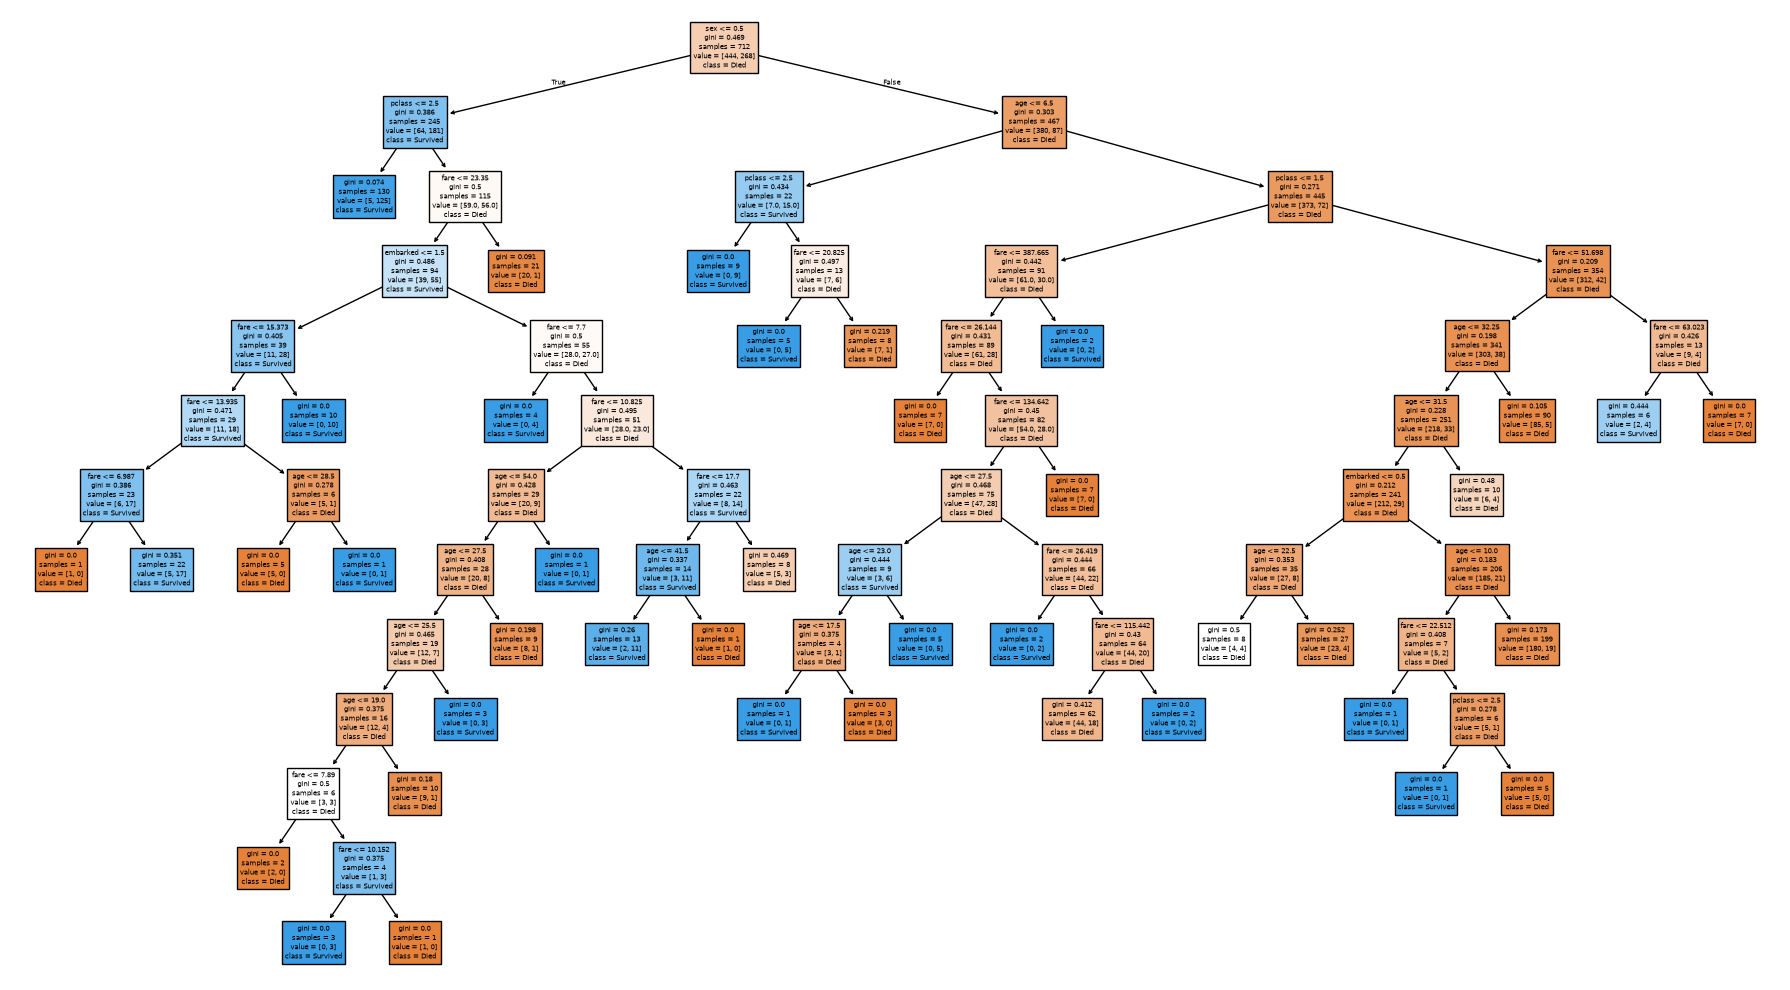

In [69]:
plt.figure(figsize=(18,10))

plot_tree(
    best_model,
    feature_names=x.columns,
    class_names=["Died","Survived"],
    filled=True,
    
    
)

plt.tight_layout()
plt.show()